---
authors:
  - name: Matthias Aengenheyster
    url: https://www.linkedin.com/in/matthias-aengenheyster-2a0ba5199/
---

# Day 15 · Inside out — The ocean's currents, inside out

<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

### #30DayMapChallenge 2026 · DestinE Climate DT via Polytope · Map by Matthias Aengenheyster

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

A companion to Emma Pidduck's
[Day 15](https://github.com/piddy376/30dmc2026/blob/main/day15_inside_out.ipynb), which turns the
map inside out with the **Spilhaus projection** and puts ocean *waves* on it. Spilhaus cuts
through the continents and keeps the ocean in one piece, with Antarctica in the middle. This
notebook puts the ocean's *currents* on the same canvas, with the sea ice, for every day of a
model month.

The **DestinE Climate DT** runs the Earth system at kilometre scale for decades, so a global
map of surface currents is full of **eddies a few tens of km across** — the Gulf Stream, the
Agulhas retroflection and the Antarctic Circumpolar Current all show up as filaments, rings and
meanders rather than as smooth arrows. The archive is far too large to download, and
**Polytope** is how you use it anyway: each day is one small request to the data bridge.

## Method

- **The data:** Climate DT phase 2 (IFS-NEMO, `hist`), **daily means** of the eastward and
  northward sea-water velocity in the **top ocean layer** (`avg_uoe`, `avg_von`; `levtype=o3d`,
  `levelist=1`), and of the **sea-ice area fraction** (`avg_siconc`; `levtype=o2d`).
  Published on HEALPix nside 1024 (6.4 km), nested.
- **The speed:** `sqrt(u² + v²)` of the daily-mean currents, in m/s.
- **The ice:** concentration of 15 % or more is drawn over the currents, in a separate, cool
  ramp so the two never read as one field. Sea-ice *area* — concentration × cell area, summed
  per hemisphere — goes in the strip under the map.
- **The map:** cartopy has a `Spilhaus` projection. Every pixel of the image is turned into a
  longitude/latitude, then into a HEALPix cell, and coloured with that cell's value — the
  `nnshow` recipe of Days 14 and 20. That pixel→cell lookup is the same on every frame, so it is
  computed **once**, and each day only costs a table lookup.
- **Land is a void.** NEMO has no values over land, so the continents stay as the empty
  frame around the ocean.

**One caveat:** the Climate DT historical run is *free-running*. Its eddies and its ice edge
are those of a model year with realistic statistics, not the observed day shown in the date.

## Licence & attribution

**DestinE Climate DT** phase 2 is available to anyone with a
[DestinE account](https://platform.destine.eu/) through **Polytope**.

`© ECMWF / Destination Earth` · Destination Earth is funded by the European Union and
implemented by ECMWF, ESA and EUMETSAT.

## Tools

| Tool | Role |
|---|---|
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | the Polytope source |
| [`healpy`](https://healpy.readthedocs.io) | pixel → HEALPix-cell lookup |
| [`cartopy`](https://scitools.org.uk/cartopy/docs/latest/) (≥ 0.25 for `Spilhaus`) · [`matplotlib`](https://matplotlib.org) | projection and figure |
| [`ffmpeg`](https://ffmpeg.org) (optional) | the animation |

```bash
pip install earthkit-data polytope-client healpy "cartopy>=0.25" matplotlib
```

Authentication: a DestinE account, then `desp-authentication.py` from
[polytope-examples](https://github.com/destination-earth-digital-twins/polytope-examples);
the token caches in `~/.polytopeapirc`.

### Configuration

Set the environment variable `MAP_CACHE` to keep the per-day cache somewhere other than `data/`.

The default is **one month** and takes about **4 minutes**: one small request pair per day, about
6 s each. Every day is cached, so a re-run is instant. Set `FULL_TWO_YEARS = True` for the whole
of 2013–2014 — 730 days, roughly 75 minutes of requests the first time.

`SOURCE = "bridge"` reads the same fields from the data bridge on disk instead of through
Polytope. That only works where the bridge is mounted (ECMWF's own systems); set the environment
variable `BRIDGE_ROOT` to the directory holding `o3d/daily.parq` and `daily.parq`. Everybody else uses
`"polytope"`.

In [1]:
import warnings, logging, os, shutil, subprocess, time
warnings.filterwarnings("ignore"); logging.disable(logging.INFO)   # polytope narrates every request

START, END        = "2013-07-01", "2013-07-31"
FULL_TWO_YEARS    = False            # True: 2013-01-01 .. 2014-12-31
SOURCE            = "polytope"       # "polytope" (everyone) or "bridge" (ECMWF only: data already on disk)
POSTER_DAY        = END              # the day for the still image
MAKE_VIDEO        = True

if FULL_TWO_YEARS:
    START, END = "2013-01-01", "2014-12-31"
    # POSTER_DAY = "2013-10-28"
    POSTER_DAY = "2013-07-31"

ADDR      = "polytope.mn5.apps.dte.destination-earth.eu"     # this site serves IFS-NEMO
BRIDGE    = os.environ.get("BRIDGE_ROOT")      # SOURCE = "bridge" only: the directory holding o3d/daily.parq and daily.parq
CACHE_DIR = os.path.join(os.environ.get("MAP_CACHE", "data"), "day15_currents")   # set MAP_CACHE to keep the cache elsewhere
VIDEO     = os.path.join(os.environ.get("MAP_OUT", "."),    # set MAP_OUT to write the video elsewhere
                         "day15_inside_out_currents" + ("_2013-2014" if FULL_TWO_YEARS else "") + ".mp4")
POSTER    = "day15_inside_out_currents.png"

FIG_W, FIG_H, DPI = 10.0, 13.6, 180   # inches, inches, dots per inch -> 1800 x 2448 px
MAP_IN            = 9.2               # the Spilhaus square, in inches
N                 = int(MAP_IN * DPI) # one image pixel per figure pixel
NSIDE             = 1024              # Climate DT "high" is published on HEALPix nside 1024
NPIX              = 12 * NSIDE ** 2
VMAX              = 1.0               # top of the current-speed scale, m/s
ICE_MIN           = 0.15              # ice below this concentration is not drawn

DATES = [d.strftime("%Y-%m-%d") for d in __import__("pandas").date_range(START, END)]
os.makedirs(CACHE_DIR, exist_ok=True)
print(f"{len(DATES)} days, {DATES[0]} -> {DATES[-1]}, source: {SOURCE}, image {N} x {N} px")

31 days, 2013-07-01 -> 2013-07-31, source: polytope, image 1655 x 1655 px


## Helpers

**`Lookup`** turns the Spilhaus image grid into HEALPix cell numbers — once. `sample` then
fills an image from a full-sphere field with a single indexing operation.

**`get_day`** returns one day as the pixel samples of the speed and the ice, plus the hemispheric
ice areas. It reads the cache if it can, otherwise it fetches. Caching the *samples* rather
than the 12.6-million-cell fields keeps a day to about 13 MB instead of 100.

In [2]:
import numpy as np, healpy as hp, pandas as pd
import cartopy.crs as ccrs
import earthkit.data

earthkit.data.config.set("cache-policy", "off")
PROJ, PC = ccrs.Spilhaus(), ccrs.PlateCarree()
CELL_KM2 = 4 * np.pi * 6371.0 ** 2 / NPIX          # HEALPix cells are equal-area

class Lookup:
    """Pixel -> HEALPix cell for an n x n image over the whole Spilhaus square."""
    def __init__(self, n, extent):
        x0, x1, y0, y1 = extent
        X, Y = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
        ll = PC.transform_points(PROJ, X, Y, np.zeros_like(X))
        self.ok = np.all(np.isfinite(ll), axis=-1)
        p = ll[self.ok].T
        self.pix = hp.ang2pix(NSIDE, theta=p[0], phi=p[1], nest=True, lonlat=True)
        self.n = n
    def sample(self, field):                      # full-sphere field -> 1D samples
        return field[self.pix].astype("f4")
    def image(self, samples):                     # 1D samples -> n x n image, NaN elsewhere
        img = np.full((self.n, self.n), np.nan, "f4")
        img[self.ok] = samples
        return img

_ll = hp.pix2ang(NSIDE, np.arange(NPIX), nest=True, lonlat=True)[1]
NORTH = _ll > 0                                   # which hemisphere each cell is in
del _ll

REQ = {"class": "d1", "dataset": "climate-dt", "type": "fc", "expver": "0001",
       "generation": "2", "realization": "1", "activity": "baseline", "experiment": "hist",
       "resolution": "high", "stream": "clte", "model": "IFS-NEMO", "time": "0000"}

def fetch_polytope(date):
    """One day, two requests: the top-layer currents (o3d) and the sea ice (o2d)."""
    d = date.replace("-", "")
    uv = earthkit.data.from_source("polytope", "destination-earth",
            dict(REQ, date=d, levtype="o3d", levelist="1", param="263506/263505"),
            address=ADDR, stream=False).to_fieldlist()
    ic = earthkit.data.from_source("polytope", "destination-earth",
            dict(REQ, date=d, levtype="o2d", param="263001"),
            address=ADDR, stream=False).to_fieldlist()
    f = {x.metadata("shortName"): x.values for x in list(uv) + list(ic)}
    return f["avg_uoe"], f["avg_von"], f["avg_siconc"]

_bridge = {}
def fetch_bridge(date):
    """The same three fields from the zarr references of the data bridge, read in place."""
    import xarray as xr
    if not BRIDGE:
        raise RuntimeError("SOURCE = 'bridge' needs the BRIDGE_ROOT environment variable "
                           "(the directory with o3d/daily.parq and daily.parq)")
    if not _bridge:
        kw = dict(consolidated=False)
        _bridge["o3d"] = xr.open_zarr("reference::" + os.path.join(BRIDGE, "o3d/daily.parq"), **kw)
        _bridge["o2d"] = xr.open_zarr("reference::" + os.path.join(BRIDGE, "daily.parq"), **kw)
    o3, o2 = _bridge["o3d"], _bridge["o2d"]
    sel = lambda a, **k: a.sel(time=date, **k).squeeze().values
    return (sel(o3["avg_uoe"], level=1), sel(o3["avg_von"], level=1), sel(o2["avg_siconc"]))

def get_day(date, lk):
    path = f"{CACHE_DIR}/{date}_n{lk.n}.npz"
    if os.path.exists(path):
        z = np.load(path)
        return z["speed"], z["ice"], float(z["north"]), float(z["south"])
    u, v, c = (fetch_polytope if SOURCE == "polytope" else fetch_bridge)(date)
    clean = lambda a: np.where(np.abs(a) > 1e3, np.nan, a)           # missing value is 9999
    speed, ice = np.hypot(clean(u), clean(v)), clean(c)
    shown = np.where(ice >= ICE_MIN, ice, np.nan)
    area = lambda m: float(np.nansum(np.where(m, shown, np.nan)) * CELL_KM2 / 1e6)   # million km2
    out = (lk.sample(speed).astype("f2"), lk.sample(shown).astype("f2"), area(NORTH), area(~NORTH))
    np.savez_compressed(path, speed=out[0], ice=out[1], north=out[2], south=out[3])
    return out

## The data

One request per field and day. The first call takes a moment longer — it also builds the
pixel lookup.

In [3]:
import matplotlib
import matplotlib.pyplot as plt

# the lookup needs the axes limits of the projection, so read them from a throwaway axes
_f = plt.figure(); _a = _f.add_subplot(projection=PROJ); _a.set_global()
EXTENT = (*_a.get_xlim(), *_a.get_ylim()); plt.close(_f)
LK = Lookup(N, EXTENT)

t0 = time.time()
ARC, ANT = [], []                       # only the ice areas stay in memory; frames re-read the cache
for i, date in enumerate(DATES):
    s, ic, a, b = get_day(date, LK)
    ARC.append(a); ANT.append(b)
    if i % 5 == 0 or i == len(DATES) - 1:
        print(f"  {date}  {i + 1:>3}/{len(DATES)}  {time.time() - t0:>5.0f} s", flush=True)
ARC, ANT = np.array(ARC), np.array(ANT)
print(f"peak speed {np.nanmax(s):.2f} m/s on {DATES[-1]} · "
      f"ice area: Arctic {ARC.min():.1f}-{ARC.max():.1f}, Antarctic {ANT.min():.1f}-{ANT.max():.1f} million km²")

  2013-07-01    1/31      0 s


  2013-07-06    6/31      0 s


  2013-07-11   11/31      0 s


  2013-07-16   16/31      0 s


  2013-07-21   21/31      1 s


  2013-07-26   26/31      1 s


  2013-07-31   31/31      1 s


peak speed 3.61 m/s on 2013-07-31 · ice area: Arctic 5.3-7.6, Antarctic 14.5-16.7 million km²


## The figure

One layout, built once; every frame only swaps the two images and moves the marker on the strip.
Land and the empty corners are a dark void, the currents run from black (still) to white-hot
(1 m/s or more), and the ice is a pale-blue-to-white ramp that cannot be mistaken for them.

saved day15_inside_out_currents.png


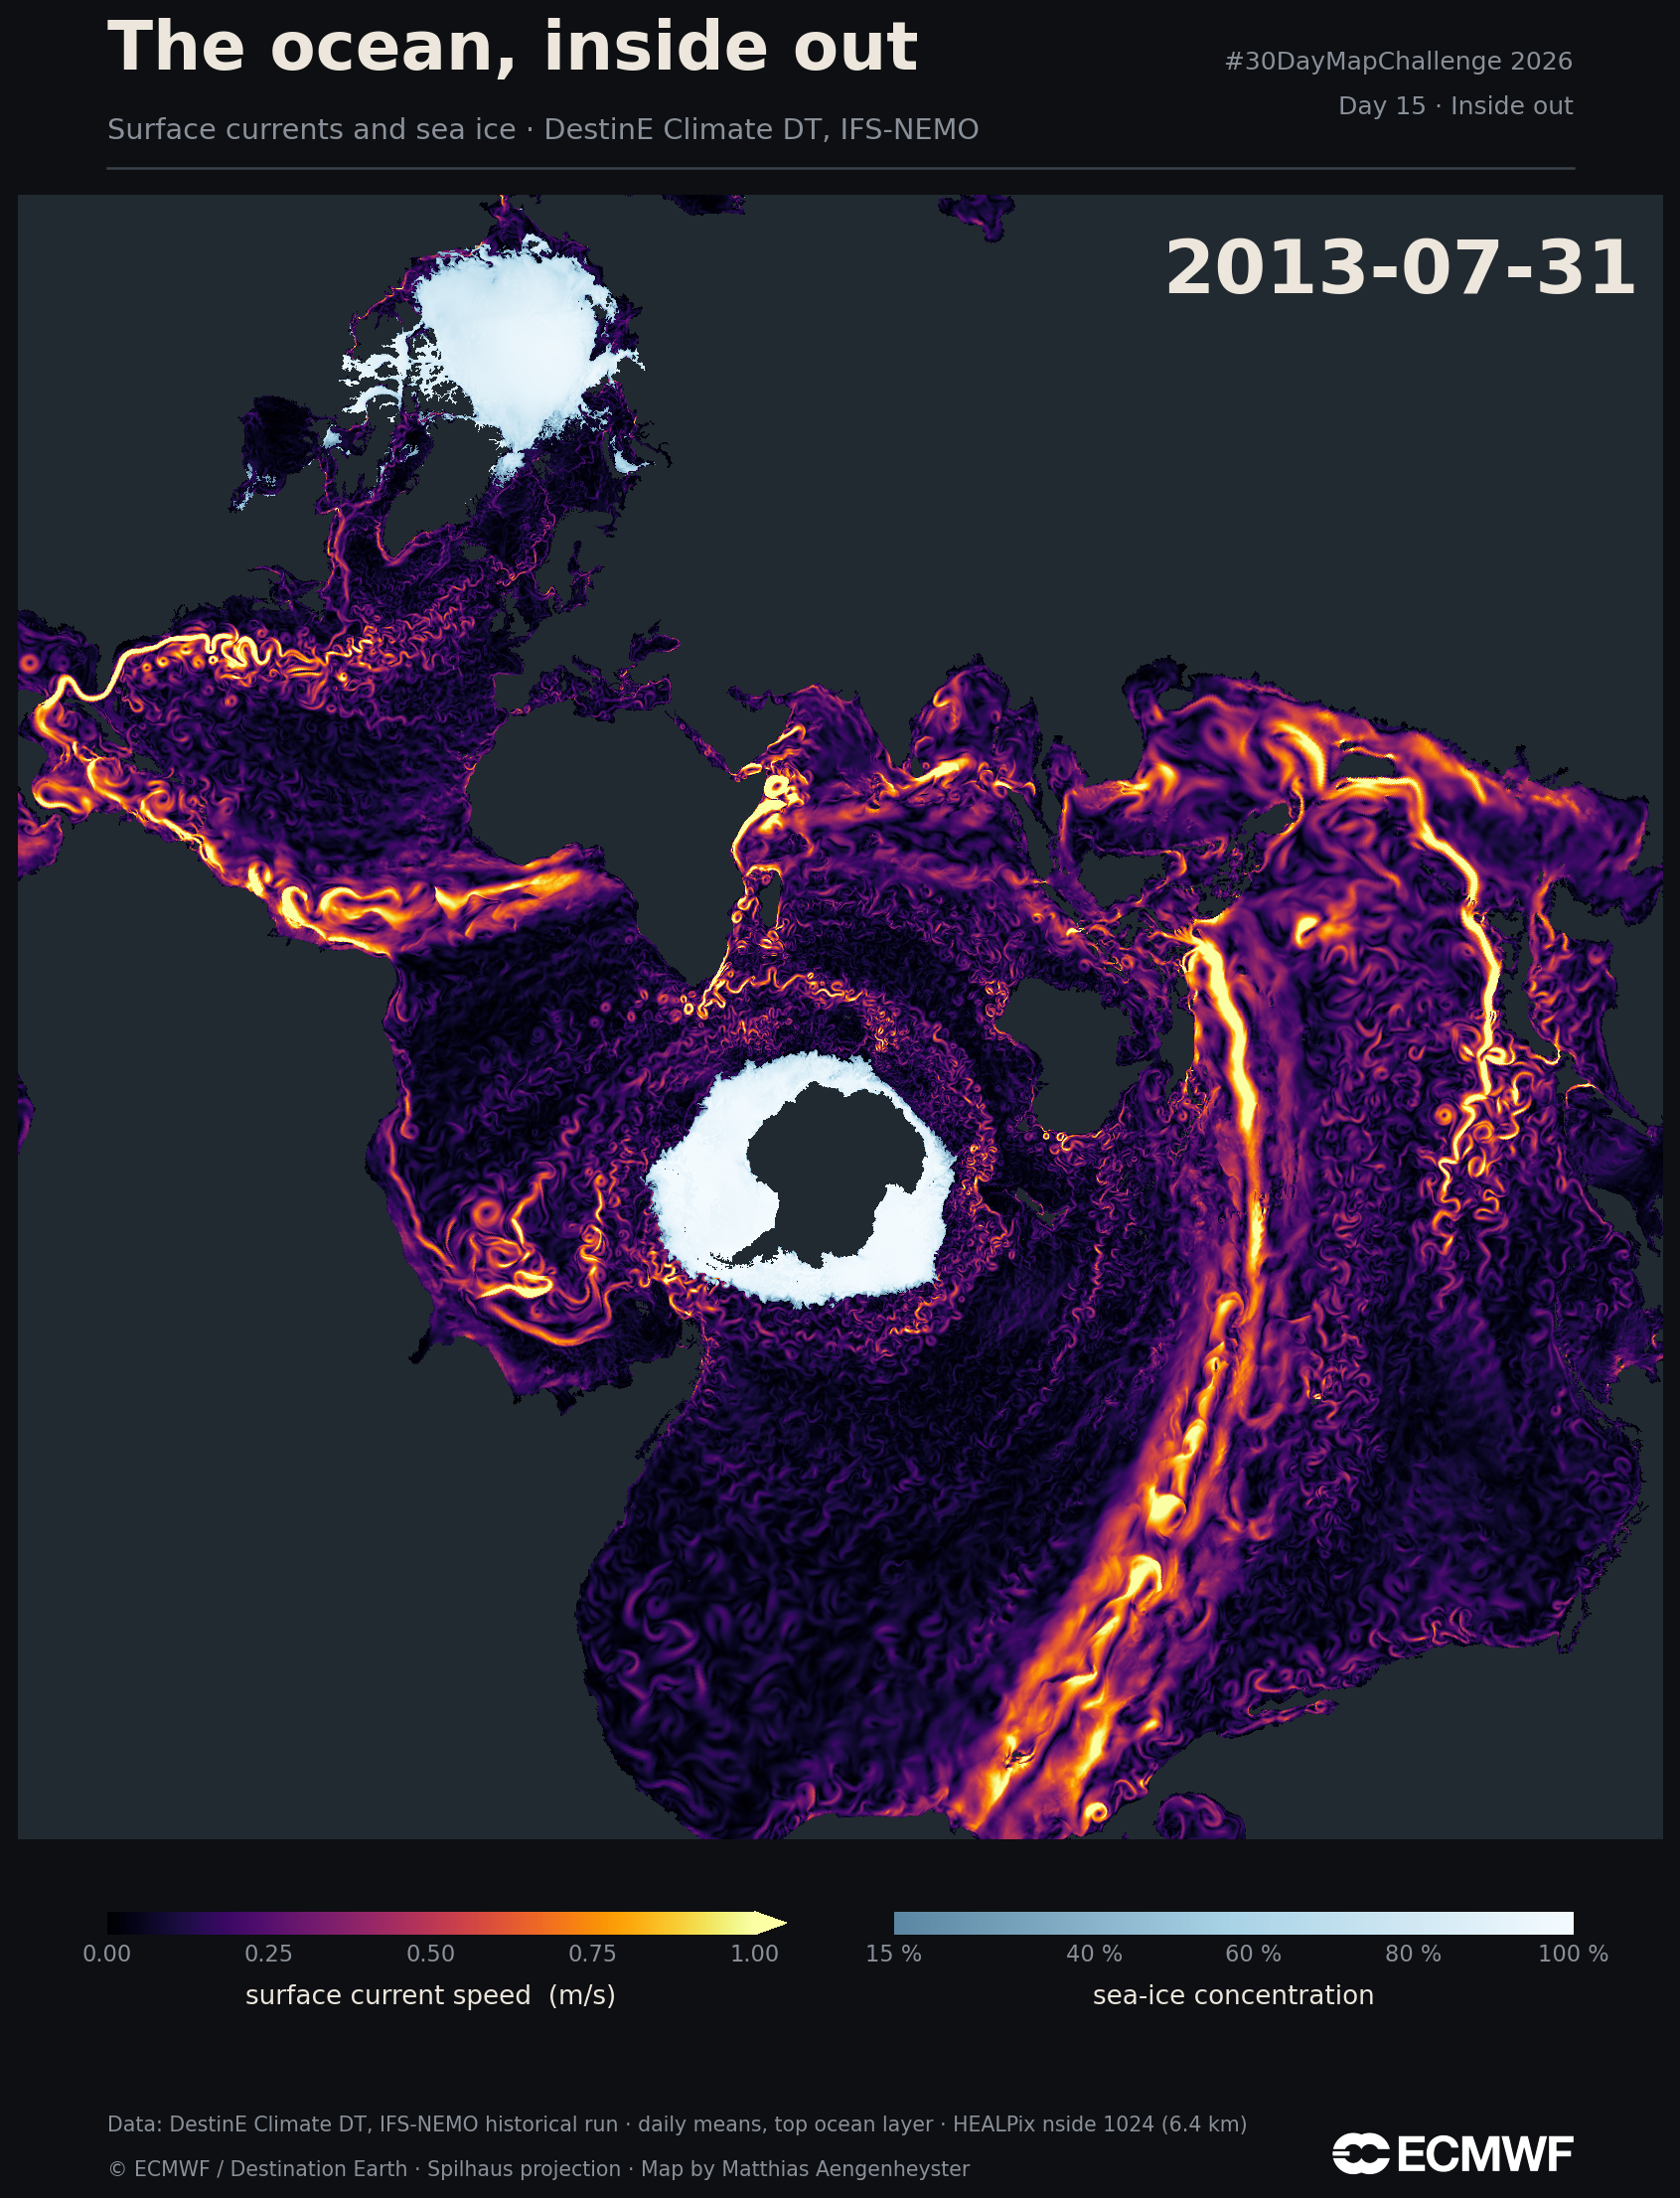

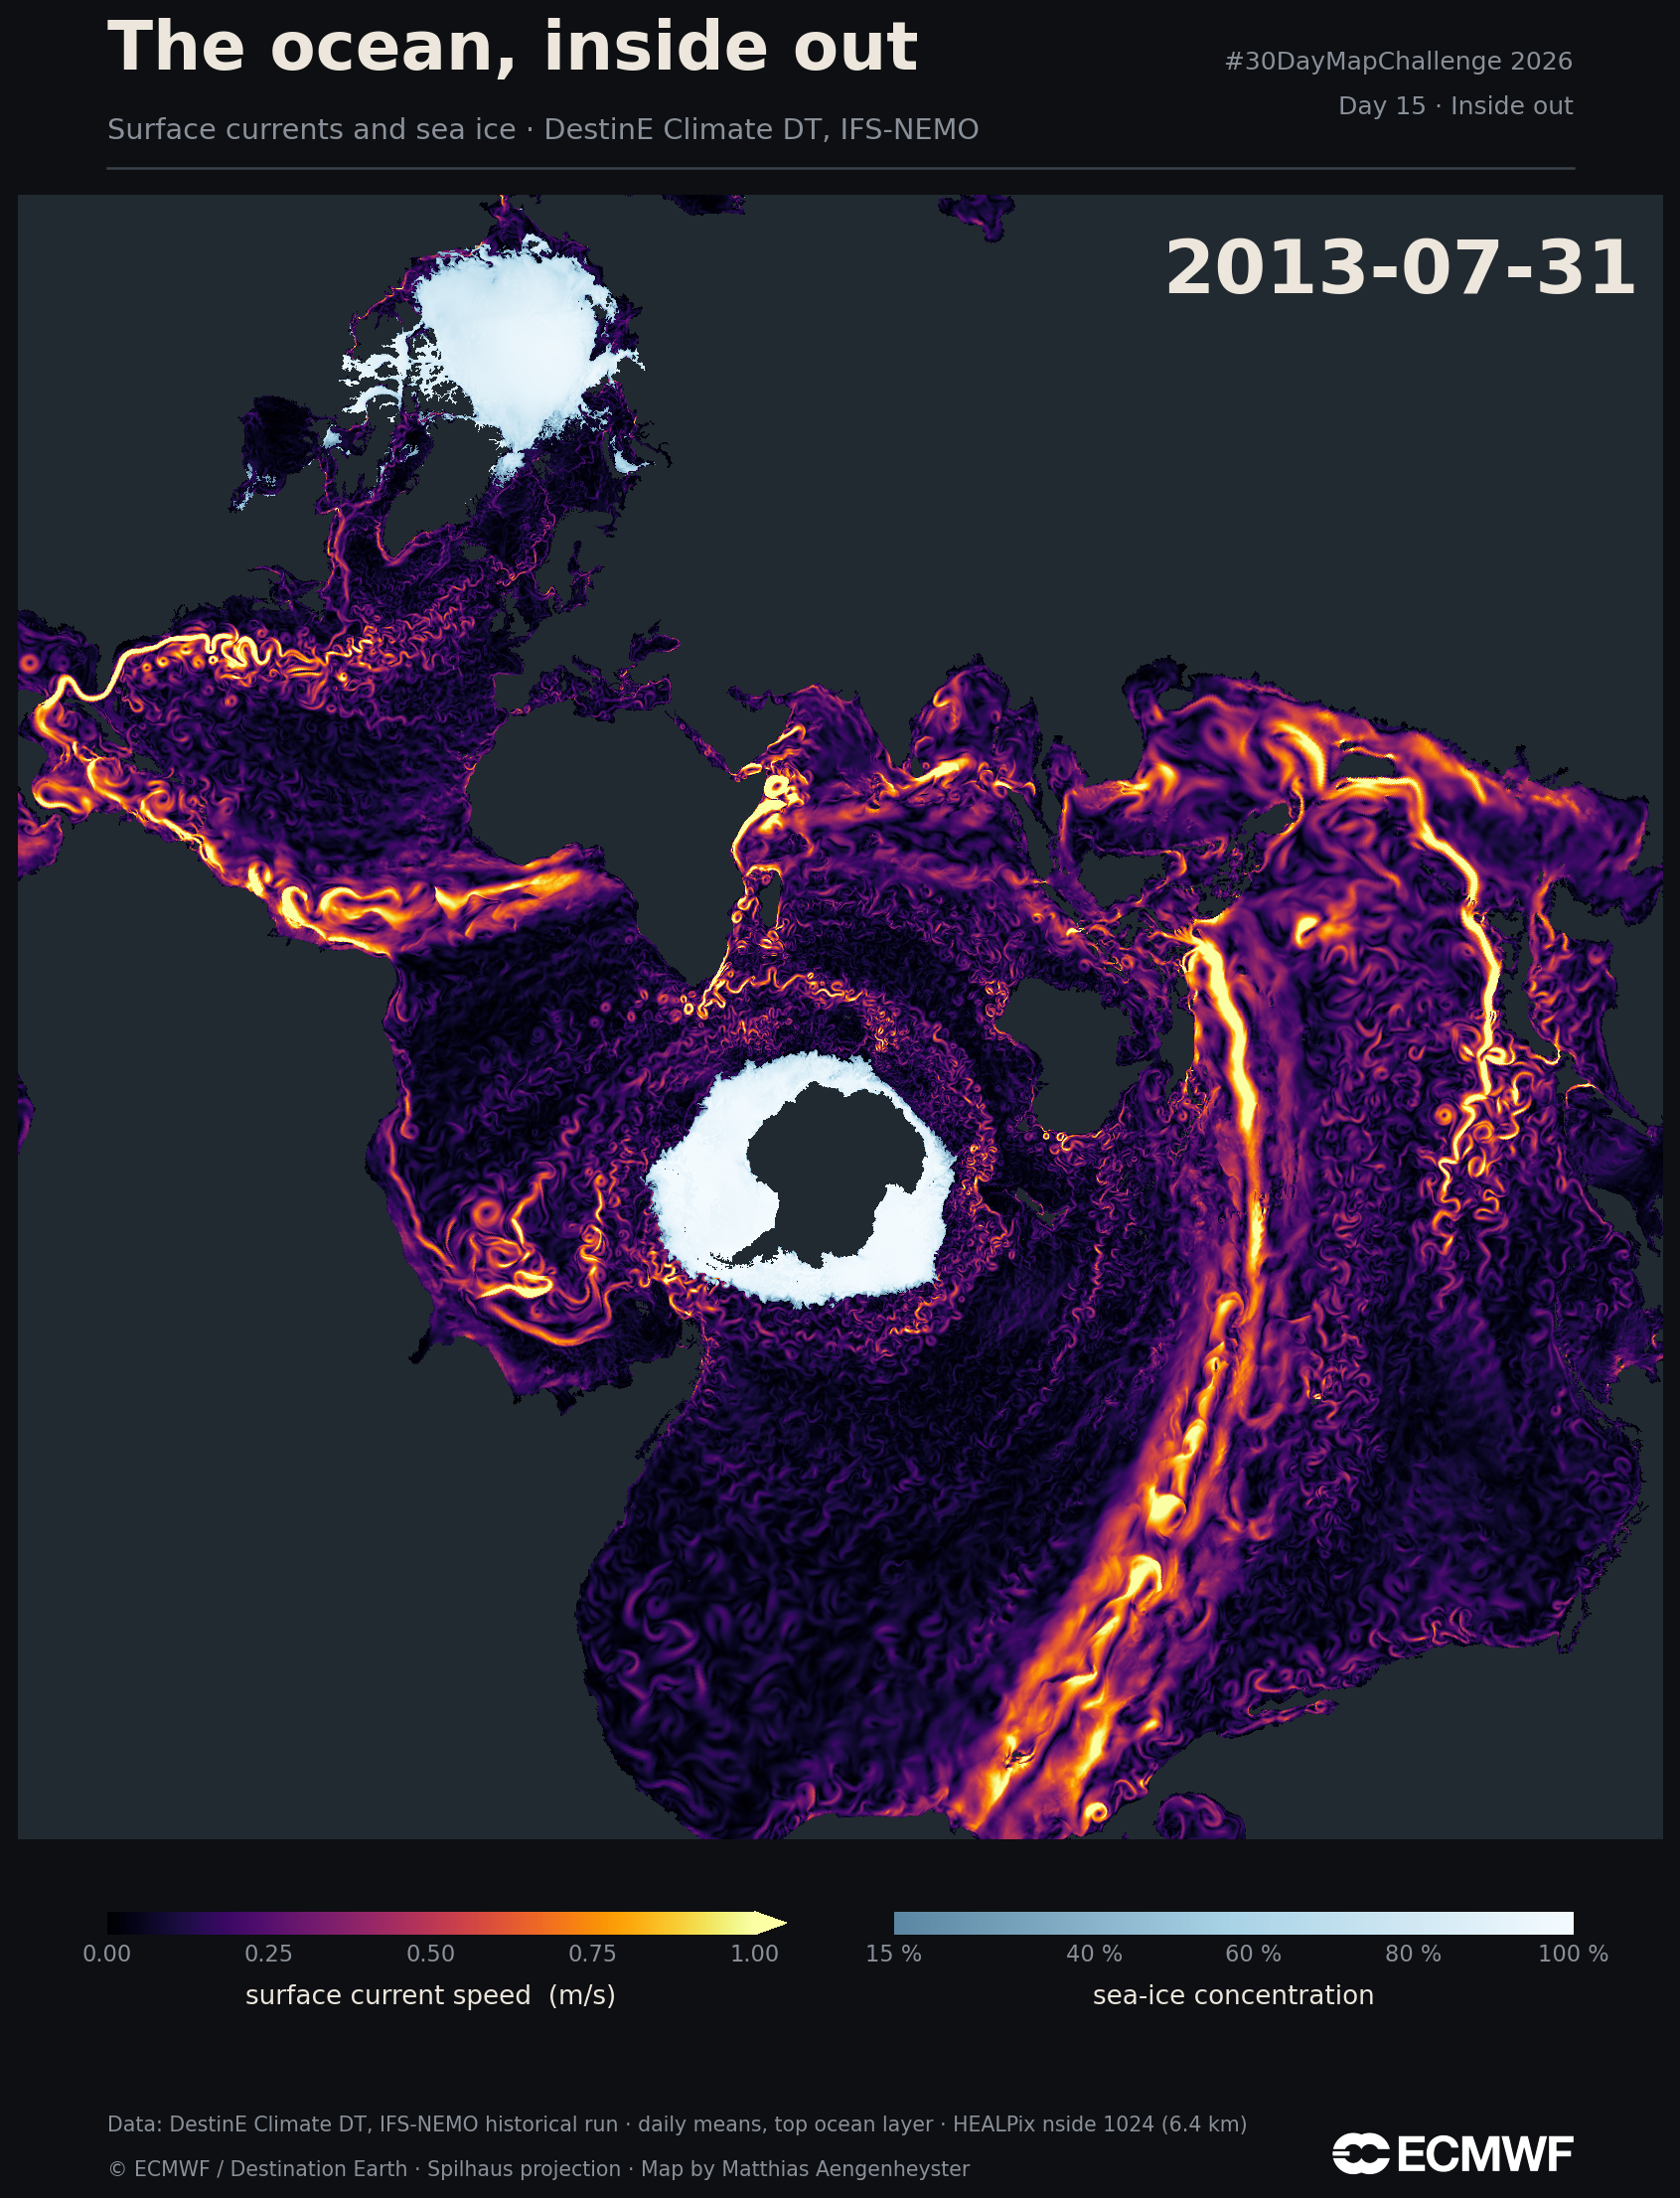

In [4]:
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.image as mpimg

BG, INK, MUT, LAND, EDGE = "#0d0f12", "#ece6dc", "#8a9099", "#222a31", "#3a424b"
C_ARC, C_ANT = "#e6c98d", "#7fbfe8"
CMAP_SPEED = plt.get_cmap("inferno")
CMAP_ICE   = LinearSegmentedColormap.from_list("seaice", ["#5b86a3", "#a9d3e6", "#f4fbff"])
NORM_SPEED, NORM_ICE = Normalize(0, VMAX), Normalize(ICE_MIN, 1.0)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

t_axis = pd.to_datetime(DATES)

def build(strip=True):
    """strip=False is the poster: the sea-ice strip goes, and the layout closes up over the gap."""
    dy = 0.0 if strip else 1.0
    H = FIG_H - dy
    Y = lambda y: y - dy if y > 2.0 else y                           # everything above the strip moves down
    fy = lambda y: Y(y) / H
    fig = plt.figure(figsize=(FIG_W, H), dpi=DPI, facecolor=BG)
    box = lambda x, y, w, h: [x / FIG_W, Y(y) / H, w / FIG_W, h / H]   # inches -> figure fractions
    A = {}

    ax = fig.add_axes(box((FIG_W - MAP_IN) / 2, 3.15, MAP_IN, MAP_IN), projection=PROJ)
    ax.set_global(); ax.set_facecolor(LAND); ax.spines["geo"].set_visible(False)
    blank = np.full((N, N), np.nan, "f4")
    A["speed"] = ax.imshow(blank, extent=EXTENT, origin="lower", cmap=CMAP_SPEED, norm=NORM_SPEED,
                           interpolation="nearest", zorder=2)
    A["ice"] = ax.imshow(blank, extent=EXTENT, origin="lower", cmap=CMAP_ICE, norm=NORM_ICE,
                         interpolation="nearest", zorder=3)
    A["date"] = ax.text(0.985, 0.975, "", transform=ax.transAxes, ha="right", va="top",
                        color=INK, fontsize=30, fontweight="bold", zorder=5)

    # colourbars
    for x, cmap, norm, ticks, lab, ext in (
            (0.9, CMAP_SPEED, NORM_SPEED, [0, 0.25, 0.5, 0.75, 1.0], "surface current speed  (m/s)", "max"),
            (5.3, CMAP_ICE, NORM_ICE, [0.15, 0.4, 0.6, 0.8, 1.0], "sea-ice concentration", "neither")):
        cax = fig.add_axes(box(x, 2.62, 3.8, 0.13))
        cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal",
                          ticks=ticks, extend=ext)
        if "ice" in lab:
            cb.ax.set_xticklabels([f"{int(round(t * 100))} %" for t in ticks])
        cb.set_label(lab, color=INK, fontsize=10.5, labelpad=7)
        cb.ax.tick_params(labelsize=9, colors=MUT, length=0); cb.outline.set_visible(False)

    if strip:
        # sea-ice strip: both hemispheres, revealed as the animation plays
        st = fig.add_axes(box(0.9, 1.05, 8.2, 1.0)); st.set_facecolor(BG)
        st.set_xlim(t_axis[0], t_axis[-1])
        st.set_ylim(0, 22); st.set_yticks([0, 10, 20])
        st.set_ylabel("sea-ice area\n(million km²)", color=MUT, fontsize=9.5, labelpad=8)
        st.grid(True, axis="y", color="#1f242b", lw=0.8); st.set_axisbelow(True)
        for s in ("top", "right"): st.spines[s].set_visible(False)
        for s in ("left", "bottom"): st.spines[s].set_color(EDGE)
        if len(DATES) <= 62:                          # a month: weekly ticks, "08 Jul"
            st.xaxis.set_major_locator(mdates.DayLocator(interval=7))
            st.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
        else:                                         # years: quarterly ticks
            st.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
            st.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        st.tick_params(colors=MUT, labelsize=9, length=0)
        A["line_arc"], = st.plot([], [], color=C_ARC, lw=2.0, label="Arctic")
        A["line_ant"], = st.plot([], [], color=C_ANT, lw=2.0, label="Antarctic")
        A["dot_arc"], = st.plot([], [], "o", color=C_ARC, ms=6.5, zorder=5, clip_on=False)
        A["dot_ant"], = st.plot([], [], "o", color=C_ANT, ms=6.5, zorder=5, clip_on=False)
        st.legend(frameon=False, fontsize=9.5, loc="upper left", ncol=2, labelcolor=INK,
                  handlelength=1.4, borderaxespad=0.2)

    # header and footer
    fig.text(0.9 / FIG_W, fy(13.05), "The ocean, inside out", color=INK, fontsize=27, fontweight="bold")
    fig.text(0.9 / FIG_W, fy(12.66),
             "Surface currents and sea ice · DestinE Climate DT, IFS-NEMO",
             color=MUT, fontsize=11.5)
    fig.text(9.1 / FIG_W, fy(13.05), "#30DayMapChallenge 2026", color=MUT, fontsize=10, ha="right")
    fig.text(9.1 / FIG_W, fy(12.80), "Day 15 · Inside out", color=MUT, fontsize=10, ha="right")
    fig.lines.append(plt.Line2D([0.9 / FIG_W, 9.1 / FIG_W], [fy(12.50)] * 2,
                                transform=fig.transFigure, color=EDGE, lw=1.0))
    fig.text(0.9 / FIG_W, fy(0.52),
             "Data: DestinE Climate DT, IFS-NEMO historical run · daily means, top ocean layer · "
             "HEALPix nside 1024 (6.4 km)", color=MUT, fontsize=8.2)
    fig.text(0.9 / FIG_W, fy(0.27), "© ECMWF / Destination Earth · Spilhaus projection · "
             "Map by Matthias Aengenheyster", color=MUT, fontsize=8.2)
    try:
        la = fig.add_axes(box(7.75, 0.22, 1.35, 0.35)); la.imshow(mpimg.imread("assets/ECMWF_Core_Logo_WHITE.png"))
        la.axis("off")
    except FileNotFoundError:
        pass
    return fig, A

def draw(fig, A, i, reveal_all=False):
    """Put day i on the figure."""
    speed, ice, _, _ = get_day(DATES[i], LK)            # a cache hit: the data cell has fetched everything
    A["speed"].set_data(LK.image(speed.astype("f4")))
    A["ice"].set_data(LK.image(ice.astype("f4")))
    A["date"].set_text(DATES[i])
    if "line_arc" not in A:                       # the poster has no strip
        return
    n = len(DATES) if reveal_all else i + 1
    A["line_arc"].set_data(t_axis[:n], ARC[:n]); A["line_ant"].set_data(t_axis[:n], ANT[:n])
    A["dot_arc"].set_data([t_axis[i]], [ARC[i]]); A["dot_ant"].set_data([t_axis[i]], [ANT[i]])

fig, A = build(strip=False)                      # the poster is the map alone
j = DATES.index(POSTER_DAY)
draw(fig, A, j)
fig.savefig(POSTER, facecolor=BG)
print("saved", POSTER)
fig

## The animation

The same figure, redrawn once per day and piped straight into `ffmpeg` — no folder of PNGs. The
output is H.264, yuv420p, so it plays everywhere, phones included.

In [5]:
FFMPEG = shutil.which("ffmpeg")
if not (MAKE_VIDEO and FFMPEG):
    print("skipped: no ffmpeg on the PATH" if MAKE_VIDEO else "skipped: MAKE_VIDEO is False")
else:
    fig, A = build()
    W, H = int(FIG_W * DPI), int(FIG_H * DPI)
    cmd = [FFMPEG, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgba", "-s", f"{W}x{H}",
           "-framerate", "24", "-i", "-", "-c:v", "libx264", "-profile:v", "high", "-level", "5.1",
           "-pix_fmt", "yuv420p", "-crf", "20", "-movflags", "+faststart", VIDEO]
    ff = subprocess.Popen(cmd, stdin=subprocess.PIPE)
    t0 = time.time()
    for i in range(len(DATES)):
        draw(fig, A, i)
        fig.canvas.draw()
        ff.stdin.write(fig.canvas.buffer_rgba())
        if i % 10 == 0:
            print(f"  frame {i + 1:>3}/{len(DATES)}  {time.time() - t0:>5.0f} s", flush=True)
    ff.stdin.close(); ff.wait(); plt.close(fig)
    print(f"saved {VIDEO}  ({os.path.getsize(VIDEO) / 1e6:.1f} MB)")

  frame   1/31      1 s


  frame  11/31      8 s


  frame  21/31     15 s


  frame  31/31     22 s


saved ./day15_inside_out_currents.mp4  (3.8 MB)


## Note

Look at the **ring of eddies around the Antarctic ice** in the middle: the Southern Ocean is the one
basin that circles the globe unbroken, and on this map every other ocean hangs off it. The
brightest ribbons are the western boundary currents. In the strip, the Arctic and the Antarctic
ice breathe in opposite phase: in northern summer one shrinks while the other grows.

Being straight about the data: these are **daily means** of the top model layer, so anything that
changes faster than a day is smoothed out. The ice edge is the model's own and is not
assimilated, so it will not match a satellite on a given day.

Figures saved as `day15_inside_out_currents.png` and [`day15_inside_out_currents.mp4`](day15_inside_out_currents.mp4)
(the month shown here; the full 2013–2014 version is 730 frames and 88 MB, so it is not in the repository).

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and Copernicus) open data.*